<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_ap_vr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio VI, apêndice: óculos de realidade virtual

## Prever para onde a cabeça vai estar daqui a 20 ms: a Exp, um filtro de Kalman e o atraso entre o movimento e a imagem

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X6_quaternions.ipynb](X6_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_quaternions.ipynb))

**O problema.** Nuns óculos de realidade virtual, a imagem precisa acompanhar a cabeça. Mas entre ler o sensor, desenhar a cena e acender os pixels passa um tempo, o **atraso movimento-fóton**, tipicamente de 10 a 30 ms. Se a imagem for desenhada para a orientação **lida**, ela chega atrasada: numa virada de cabeça a 300 °/s, 20 ms são 6°, e o mundo virtual parece "arrastar" atrás do olhar, o que causa enjoo. A solução usada pelos fabricantes é **prever** a orientação da cabeça no instante em que a imagem vai aparecer, a partir do giroscópio (que, nos óculos, roda a 1000 Hz).

**As previsões comparadas** (todas partem da orientação atual $q(t)$, suposta conhecida, para isolar o problema da previsão):
1. **nenhuma:** desenhar para $q(t)$;
2. **velocidade constante:** $q(t)\,\mathrm{Exp}(\boldsymbol\omega\tau)$, com a última leitura do giroscópio;
3. **aceleração constante, por Kalman:** um filtro de Kalman por eixo, com estado (velocidade angular, aceleração angular) e o modelo de aceleração com ruído, estima $\boldsymbol\omega$ e $\boldsymbol\alpha$; a previsão é $q(t)\,\mathrm{Exp}(\boldsymbol\omega\tau+\tfrac12\boldsymbol\alpha\tau^2)$.

A fórmula da terceira previsão é exata quando o eixo de rotação não muda durante $\tau$ (as rotações em torno do mesmo eixo comutam); quando o eixo muda, falta o colchete de Lie do notebook VI(c). Em 20 ms, a cabeça quase não muda de eixo.

**A cabeça simulada:** viradas rápidas (de 15° a 70°, com o perfil de jerk mínimo dos movimentos humanos), em direções sorteadas, principalmente na guinada; entre elas, pausas com um tremor de 8 Hz. O giroscópio tem ruído de 0,02 rad/s por amostra. Um minuto, a 1000 Hz.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

def qmul(a, b):
    """Produto de Hamilton de quaternions guardados como arrays (w, x, y, z); aceita pilhas (..., 4)."""
    a, b = np.asarray(a), np.asarray(b)
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                     w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                     w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], axis=-1)

def qconj(q):
    q = np.asarray(q); return q * np.array([1, -1, -1, -1])

def qnorm(q):
    q = np.asarray(q, float); return q / np.linalg.norm(q, axis=-1, keepdims=True)

def qrot(q, v):
    """O vetor v (3,) levado pela rotação q: a parte vetorial de q (0, v) q*."""
    return qmul(qmul(q, np.concatenate([[0.0], v])), qconj(q))[1:]

def qmat(q):
    """A matriz de rotação R(q), com R v = q v q* (q unitário)."""
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def mat_q(R):
    """De uma matriz de rotação para um quaternion (método de Shepperd: usa o maior pivô, sem perder dígitos)."""
    t = np.trace(R); d = np.diag(R)
    k = np.argmax([t, *d])
    if k == 0:
        w = np.sqrt(1 + t) / 2; q = [w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)]
    elif k == 1:
        x = np.sqrt(1 + 2 * d[0] - t) / 2; q = [(R[2, 1] - R[1, 2]) / (4 * x), x, (R[0, 1] + R[1, 0]) / (4 * x), (R[0, 2] + R[2, 0]) / (4 * x)]
    elif k == 2:
        y = np.sqrt(1 + 2 * d[1] - t) / 2; q = [(R[0, 2] - R[2, 0]) / (4 * y), (R[0, 1] + R[1, 0]) / (4 * y), y, (R[1, 2] + R[2, 1]) / (4 * y)]
    else:
        z = np.sqrt(1 + 2 * d[2] - t) / 2; q = [(R[1, 0] - R[0, 1]) / (4 * z), (R[0, 2] + R[2, 0]) / (4 * z), (R[1, 2] + R[2, 1]) / (4 * z), z]
    q = np.array(q); return q if q[0] >= 0 else -q

def qexp(phi):
    """Exp do vetor de rotação φ = θ n: (cos(θ/2), sen(θ/2) n), com o sinc estável perto de θ = 0."""
    phi = np.asarray(phi, float); th = np.linalg.norm(phi)
    return np.concatenate([[np.cos(th / 2)], 0.5 * sinc(th / 2) * phi])

def qlog(q):
    """Log: o vetor de rotação φ de q (escolhendo o representante com w ≥ 0, isto é, |θ| ≤ π)."""
    q = np.asarray(q, float)
    if q[0] < 0: q = -q
    s = np.linalg.norm(q[1:]); th = 2 * np.arctan2(s, q[0])     # atan2: estável para ângulos pequenos e grandes
    return 2 * q[1:] / sinc(th / 2)

def slerp(q0, q1, s):
    """Interpolação esférica: q0 Exp(s Log(q0* q1)), pelo arco mais curto."""
    return qmul(q0, qexp(s * qlog(qmul(qconj(q0), q1))))

def chapeu(v):
    """A matriz antissimétrica [v]×, com [v]× u = v × u."""
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

DT, T, SIG = 0.001, 60.0, 0.02
rng = np.random.default_rng(66)
n = int(T / DT); W = np.zeros((n, 3)); k_ = 0
while k_ < n:
    k_ += int(rng.uniform(0.2, 1.0) / DT)                              # pausa
    D = rng.uniform(0.25, 0.6); A = np.radians(rng.uniform(15, 70))
    eixo = qnorm(np.array([0, *rng.normal(0, [0.15, 0.4, 1.0])]))[1:]   # sobretudo guinada (z), um pouco de arfagem
    m_ = int(D / DT)
    for j in range(min(m_, n - k_)):
        s = (j + 0.5) / m_; W[k_ + j] = A / D * (30 * s**2 - 60 * s**3 + 30 * s**4) * eixo   # jerk mínimo
    k_ += m_
W += 0.05 * np.sin(2 * np.pi * 8 * np.arange(n) * DT)[:, None] * np.array([0.3, 0.3, 0.1])   # tremor
Q = [np.array([1.0, 0, 0, 0])]
for k_ in range(n): Q.append(qmul(Q[-1], qexp(W[k_] * DT)))
Q = np.array(Q)
WM = W + SIG * rng.normal(size=W.shape)
print(f"pico da velocidade angular: {np.degrees(np.linalg.norm(W, axis=1).max()):.0f} °/s;  "
      f"fração do tempo acima de 100 °/s: {100 * np.mean(np.degrees(np.linalg.norm(W, axis=1)) > 100):.0f}%")

pico da velocidade angular: 503 °/s;  fração do tempo acima de 100 °/s: 17%


## 1. As previsões e duas conferências

Antes da cabeça simulada, dois movimentos em que a resposta é conhecida: com velocidade angular constante, a previsão de velocidade constante tem de ser exata; com aceleração angular constante num eixo fixo, a de aceleração constante também.

In [2]:
def kalman_ca(wm, qj):
    """Um filtro de Kalman por eixo, estado (ω, α), aceleração com ruído (densidade qj). Devolve (ω, α) estimados."""
    F = np.array([[1, DT], [0, 1]]); Qd = qj * np.array([[DT**3 / 3, DT**2 / 2], [DT**2 / 2, DT]])
    x = np.zeros((3, 2)); P = np.tile(np.eye(2), (3, 1, 1)); out = np.zeros((len(wm), 3, 2))
    for k_ in range(len(wm)):
        x = x @ F.T; P = F @ P @ F.T + Qd
        S = P[:, 0, 0] + SIG**2; K = P[:, :, 0] / S[:, None]
        x = x + K * (wm[k_] - x[:, 0])[:, None]
        P = P - K[:, :, None] * P[:, 0, None, :]
        out[k_] = x
    return out

tau = 0.02
eixo = np.array([0.2, -0.3, 0.93]); eixo /= np.linalg.norm(eixo)
q0 = qnorm(rng.normal(size=4)); w0, a0 = 3.0, 20.0
qt = lambda t: qmul(q0, qexp((w0 * t + 0.5 * a0 * t**2) * eixo))
qc = lambda t: qmul(q0, qexp(w0 * t * eixo))
confere("velocidade constante: q(t) Exp(ωτ) = q(t + τ)", qmul(qc(0.3), qexp(w0 * eixo * tau)), qc(0.3 + tau), tol=1e-14)
t1 = 0.3; w1 = (w0 + a0 * t1) * eixo
confere("aceleração constante num eixo fixo: q Exp(ωτ + ½ατ²) é exato",
        qmul(qt(t1), qexp(w1 * tau + 0.5 * a0 * eixo * tau**2)), qt(t1 + tau), tol=1e-14)

OK   velocidade constante: q(t) Exp(ωτ) = q(t + τ):  diferença máxima = 1.11e-16
OK   aceleração constante num eixo fixo: q Exp(ωτ + ½ατ²) é exato:  diferença máxima = 1.11e-16


## 2. Na cabeça simulada

O erro é o ângulo entre a orientação prevista e a orientação verdadeira no instante em que a imagem aparece, avaliado a cada 5 ms. A densidade do ruído de aceleração do filtro de Kalman, $q_j$, foi escolhida numa varredura (a melhor das quatro testadas, pelo erro RMS).

In [3]:
def avalia(tau, phis, passo=5):
    m_ = int(round(tau / DT)); idx = np.arange(1000, n - m_, passo)
    qp = qmul(Q[idx + 1], np.array([qexp(p_) for p_ in phis[idx]]))
    e = np.degrees([np.linalg.norm(qlog(qmul(qconj(a_), b_))) for a_, b_ in zip(qp, Q[idx + 1 + m_])])
    return np.sqrt(np.mean(e**2)), np.percentile(e, 99)

print("q_j          RMS (°)    99% (°)      com τ = 20 ms")
melhor = None
for qj in [10, 100, 1000, 10000]:
    est = kalman_ca(WM, qj)
    r_ = avalia(tau, est[:, :, 0] * tau + 0.5 * est[:, :, 1] * tau**2)
    print(f"{qj:6d}      {r_[0]:7.3f}    {r_[1]:7.3f}")
    if melhor is None or r_[0] < melhor[1][0]: melhor = (qj, r_, est)
QJ, _, EST = melhor
print(f"escolhido: q_j = {QJ}")

metodos = {"nenhuma": np.zeros((n, 3)), "velocidade constante": WM * tau,
           "Kalman (aceleração constante)": EST[:, :, 0] * tau + 0.5 * EST[:, :, 1] * tau**2}
res = {nome: avalia(tau, ph) for nome, ph in metodos.items()}
for nome, (rms, p99) in res.items():
    print(f"{nome:32s}: erro RMS {rms:6.3f}°;  em 99% do tempo, abaixo de {p99:6.3f}°")
confere("prever pela velocidade reduz o erro RMS mais de 5 vezes", res["nenhuma"][0] / res["velocidade constante"][0] > 5, True)
confere("e o Kalman com aceleração reduz de novo, mais de 2 vezes", res["velocidade constante"][0] / res["Kalman (aceleração constante)"][0] > 2, True)

q_j          RMS (°)    99% (°)      com τ = 20 ms


    10        0.145      0.638


   100        0.081      0.349


  1000        0.064      0.222


 10000        0.087      0.195
escolhido: q_j = 1000


nenhuma                         : erro RMS  1.780°;  em 99% do tempo, abaixo de  6.257°
velocidade constante            : erro RMS  0.185°;  em 99% do tempo, abaixo de  0.705°
Kalman (aceleração constante)   : erro RMS  0.064°;  em 99% do tempo, abaixo de  0.222°
OK   prever pela velocidade reduz o erro RMS mais de 5 vezes:  diferença máxima = 0.00e+00
OK   e o Kalman com aceleração reduz de novo, mais de 2 vezes:  diferença máxima = 0.00e+00


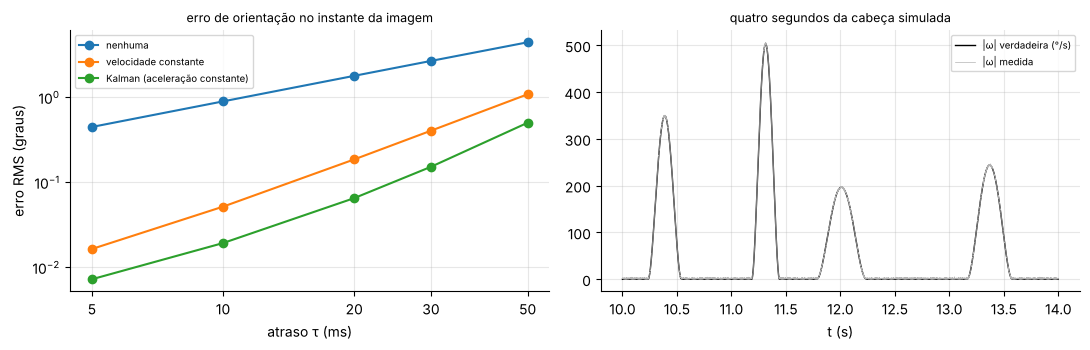

In [4]:
taus = np.array([0.005, 0.01, 0.02, 0.03, 0.05])
curvas = {nome: [] for nome in metodos}
for tt in taus:
    curvas["nenhuma"].append(avalia(tt, np.zeros((n, 3)), passo=20)[0])
    curvas["velocidade constante"].append(avalia(tt, WM * tt, passo=20)[0])
    curvas["Kalman (aceleração constante)"].append(avalia(tt, EST[:, :, 0] * tt + 0.5 * EST[:, :, 1] * tt**2, passo=20)[0])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for nome, cv in curvas.items():
    axs[0].loglog(1000 * taus, cv, "o-", label=nome)
axs[0].set_xticks([5, 10, 20, 30, 50]); axs[0].set_xticklabels(["5", "10", "20", "30", "50"]); axs[0].minorticks_off()
axs[0].set_xlabel("atraso τ (ms)"); axs[0].set_ylabel("erro RMS (graus)"); axs[0].legend(fontsize=7)
axs[0].set_title("erro de orientação no instante da imagem", fontsize=9)
jan = slice(int(10 / DT), int(14 / DT))
tt_ = np.arange(n)[jan] * DT
axs[1].plot(tt_, np.degrees(np.linalg.norm(W[jan], axis=1)), "k-", lw=1, label="|ω| verdadeira (°/s)")
axs[1].plot(tt_, np.degrees(np.linalg.norm(WM[jan], axis=1)), color="0.7", lw=0.5, label="|ω| medida")
axs[1].set_xlabel("t (s)"); axs[1].legend(fontsize=7); axs[1].set_title("quatro segundos da cabeça simulada", fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** Sem previsão, o erro no instante da imagem é de 1,8° (RMS) com 20 ms de atraso, e passa de 6° em 1% do tempo, justamente nas viradas, quando o olho mais nota. Prever pela última leitura do giroscópio, com a $\mathrm{Exp}$, reduz o erro quase 10 vezes (0,19°). O filtro de Kalman com aceleração reduz mais três vezes (0,064°; 0,22° em 99% do tempo): ele sabe que, no começo de uma virada, a velocidade ainda vai crescer, e no fim vai diminuir. A sintonia importa: com $q_j$ pequeno, o filtro acredita demais que a aceleração é constante e reage devagar; com $q_j$ grande, deixa passar o ruído do giroscópio, que a previsão multiplica por $\tau$ e por $\tau^2$.

O gráfico da esquerda mostra a regra prática: sem previsão, o erro cresce como $\tau$; com previsão de velocidade, quase como $\tau^2$ (o que sobra é a aceleração). A previsão com aceleração fica uma faixa abaixo, com inclinação parecida: o que sobra agora são as mudanças de aceleração e o ruído. Por isso os fabricantes atacam o atraso por dois lados: diminuí-lo no hardware e prever o resto no software.

## Exercícios

1. **O colchete.** Faça a cabeça virar e inclinar ao mesmo tempo (eixo que muda depressa). Compare $\mathrm{Exp}(\boldsymbol\omega\tau+\tfrac12\boldsymbol\alpha\tau^2)$ com a versão de Magnus com o colchete, $\mathrm{Exp}\big(\boldsymbol\omega\tau+\tfrac12\boldsymbol\alpha\tau^2+\tfrac1{12}\tau^3\,\boldsymbol\omega\times\boldsymbol\alpha\big)$. Em 20 ms, a diferença é visível?
2. **Prever demais.** No fim de uma virada, a cabeça desacelera; a previsão por aceleração constante passa do ponto. Meça o erro só nos instantes de desaceleração. Um modelo com amortecimento (o processo de Ornstein–Uhlenbeck do notebook I(c)) ajuda?
3. **Reprojeção.** Muitos óculos fazem uma segunda correção, depois de desenhar a imagem: medem de novo o giroscópio e giram a imagem pronta pelo erro restante (*timewarp*). Simule: previsão para 20 ms, mas com uma nova leitura 5 ms antes de acender os pixels.